# 🏷️ Addendum I: Matplotlib Stylesheets & GitHub Remote Styling

Designed by Neil Ghugare.

This is an addendum to the general professional plotting notebook.

___

Setting `plt.rcParams` at the top of every Jupyter nobteook is a huge improvement over raw default Matplotlib plots, but copying 30 liens of styling setup into every single notebook gets repetitive quickly.

By bundling your custom figure rules into a **Matplotlib Stylesheet** (`.mplstyle`) and hosting it on GitHub, you can import your signature publication theme anywhere with a single line of code!

___

## 1. Creating a Local `.mplstyle` File

A stylesheet is a plain text file containing your preferred `rcParams` settings as `key: value` pairs. Create a file with whatever name you'd like, with the extension `.mplstyle` in a project folder. Below is what that file should look like (exactly the same as the one in the notebook. In practice, I use a slightly modified one for my own personal use):
```
# Typography & fonts
font.family         : sans-serif
font.sans-serif     : DejaVu Sans, Helvetica, Arial
font.size           : 11
axes.labelsize      : 13
axes.titlesize      : 14
xtick.labelsize     : 11
ytick.labelsize     : 11
legend.fontsize     : 11

# Line and marker weights
lines.linewidth     : 1.5
patch.linewidth     : 1.0
axes.linewidth      : 1.0

# Ticks
xtick.direction     : in
ytick.direction     : in
xtick.top           : True
ytick.right         : True
xtick.minor.visible : True
ytick.minor.visible : True

# Tick sizing & length
xtick.major.size    : 6.0
xtick.minor.size    : 3.0
ytick.major.size    : 6.0
ytick.minor.size    : 3.0

# Figure layout & saving options
figure.dpi          : 150
savefig.dpi         : 300
savefig.bbox        : tight

# Grid styling
axes.grid           : True
grid.linestyle      : --
grid.alpha          : 0.5
grid.color          : gray
grid.linewidth      : 0.8
```

For now, I've saved this in the GitHub as `example.mplstyle`. If you'd like a tad more information on this (though it's not a lot), you can check out Matplotlib's [documentation](https://matplotlib.org/stable/users/explain/customizing.html#distributing-styles).

___

## 2. Using Your Local Stylesheet

Once saved, apply your theme at the start of any Python script or Jupyter Notebook:

In [4]:
import matplotlib.pyplot as plt

# Point plt to your custom style file:
plt.style.use('./example.mplstyle')

Now all created plots will still inheret all the styling guidelines, like you would with `rcParams`. This just cleans up your code!

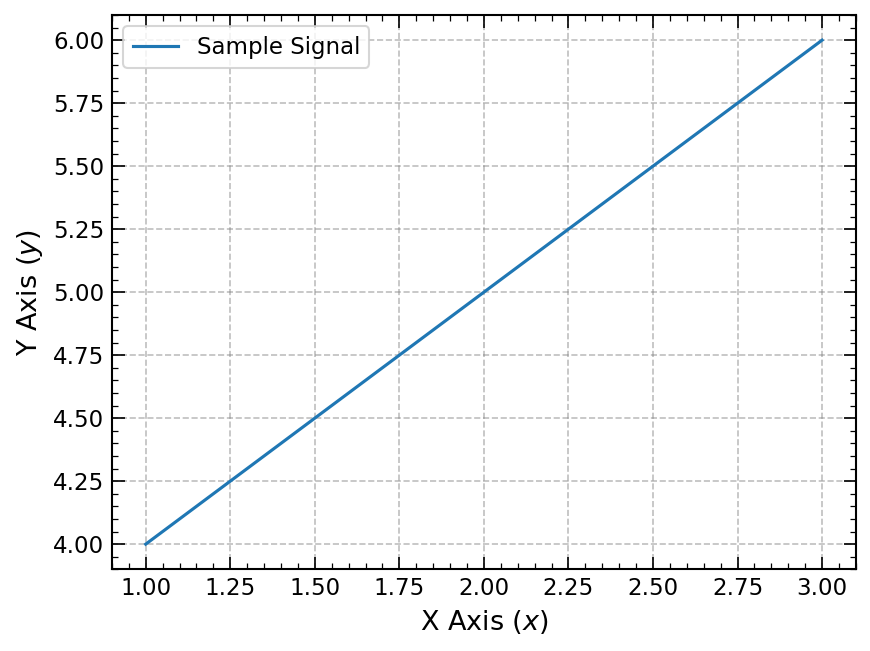

In [5]:
# Just a random example plot.
# We can see styling requirements like the grid are still applied.
fig, ax = plt.subplots()
ax.plot([1, 2, 3], [4, 5, 6], label='Sample Signal')
ax.set_xlabel('X Axis ($x$)')
ax.set_ylabel('Y Axis ($y$)')
ax.legend()
plt.show()

___

## 3. Hosting & Importing Dynamically From GitHub

Now if you look at Matplotlib's [documentation](https://matplotlib.org/stable/users/explain/customizing.html#distributing-styles), they'll explain how you can use PyPI (`pip`) to upload your stylesheet as a package to use it anywhere.

Personally, I am against this approach because PyPI cannot be used anywhere. If you switch between operation systems, environments, run scripts on institutional supercomputers, or use Google Colab, using PyPI can become challenging, and no one wants to have to copy the `example.mplstyle` everywhere. (PyPI can be challenging for numerous reasons, but one personal reason for me is that my supercomputing cluster on HiPerGator recommends Conda, not PyPI, and also hosting on Conda is another can of worms). 

So, instead, I recommend you host the `.mplstyle` file in a public GitHub repository and import it via its *Raw URL*:

### Set-by-Step Setup:
1. Push `example.mplstyle` to your public GitHub repository (has to be public). 
2. Click on the file in GitHub and press the **Raw** button in the upper right.
3. Coppy the URL (it will start with `https://raw.githubusercontent.com/`).
4. Pass that URL directly into `plt.style.use` inside Python!

Here is an example using my own personal stylesheet (which you will find is very similar to the one I provided for these notebooks! The main difference is some text sizing really):

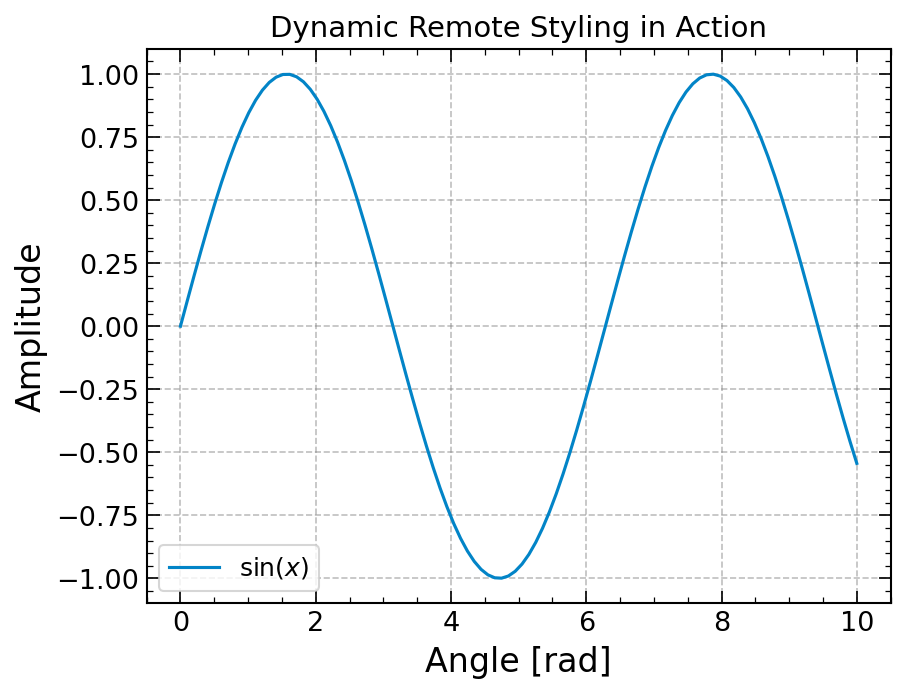

In [6]:
import numpy as np

# Load my style dynamically from GitHub!
github_style_url = 'https://raw.githubusercontent.com/RandomKiddo/astro-mpl-style/refs/heads/master/astronomy.mplstyle'

plt.style.use(github_style_url)

# Just some random sine data.
x = np.linspace(0, 10, 100)
y = np.sin(x)

# And let's check the plot:
fig, ax = plt.subplots()
ax.plot(x, y, color='#0284c7', label=r'$\sin(x)$')
ax.set_title('Dynamic Remote Styling in Action')
ax.set_xlabel('Angle [rad]')
ax.set_ylabel('Amplitude')
ax.legend()
plt.show()

> **💡 Why this is powerful for research groups:**
>
> When working on co-authored manuscripts, every co-author can reference the same GitHub Raw URL in their respective codebases. This guarantees that every figure produced by every team member shares identical fonts, line thicknesses, tick layouts, and export dimensions without any manual coordination! You can also use this across all your projects without issue, you just have to copy a singular link (which you'll start to remember as time goes on)!

And with that, you now have your own stylesheet that you can import dynamically! If you'd like to check out my GitHub repository for this, you can find it [here](https://github.com/RandomKiddo/astro-mpl-style/tree/master).